# Initial analysis: ETF allocation

Development-period observations for 2007-2015. Data from 2016 onward are excluded. The interactive report is `reports/initial_analysis.html`.

Rebuild figures: `.venv/bin/python scripts/build_initial_analysis.py`


In [1]:
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
market = pd.read_csv(ROOT / 'data/processed/market_daily.csv', parse_dates=['date']).set_index('date')
development = market.loc[:'2015-12-31'].copy()
prices = development[['spy_adj_close', 'tlt_adj_close', 'gld_adj_close']]
daily_returns = prices.pct_change(fill_method=None)
assert development.index.max() <= pd.Timestamp('2015-12-31')
print(f'Development observations: {len(development):,}; return observations: {len(daily_returns.dropna()):,}')


Development observations: 2,266; return observations: 2,265


## 01 · Asset paths from a common starting point

Compare equities, long-duration Treasuries, and gold on the same scale. Each index starts at 100; these are asset observations, not strategy returns.

**Method:** Adjusted close divided by its first observation, multiplied by 100. Cash interest and transaction costs are excluded.


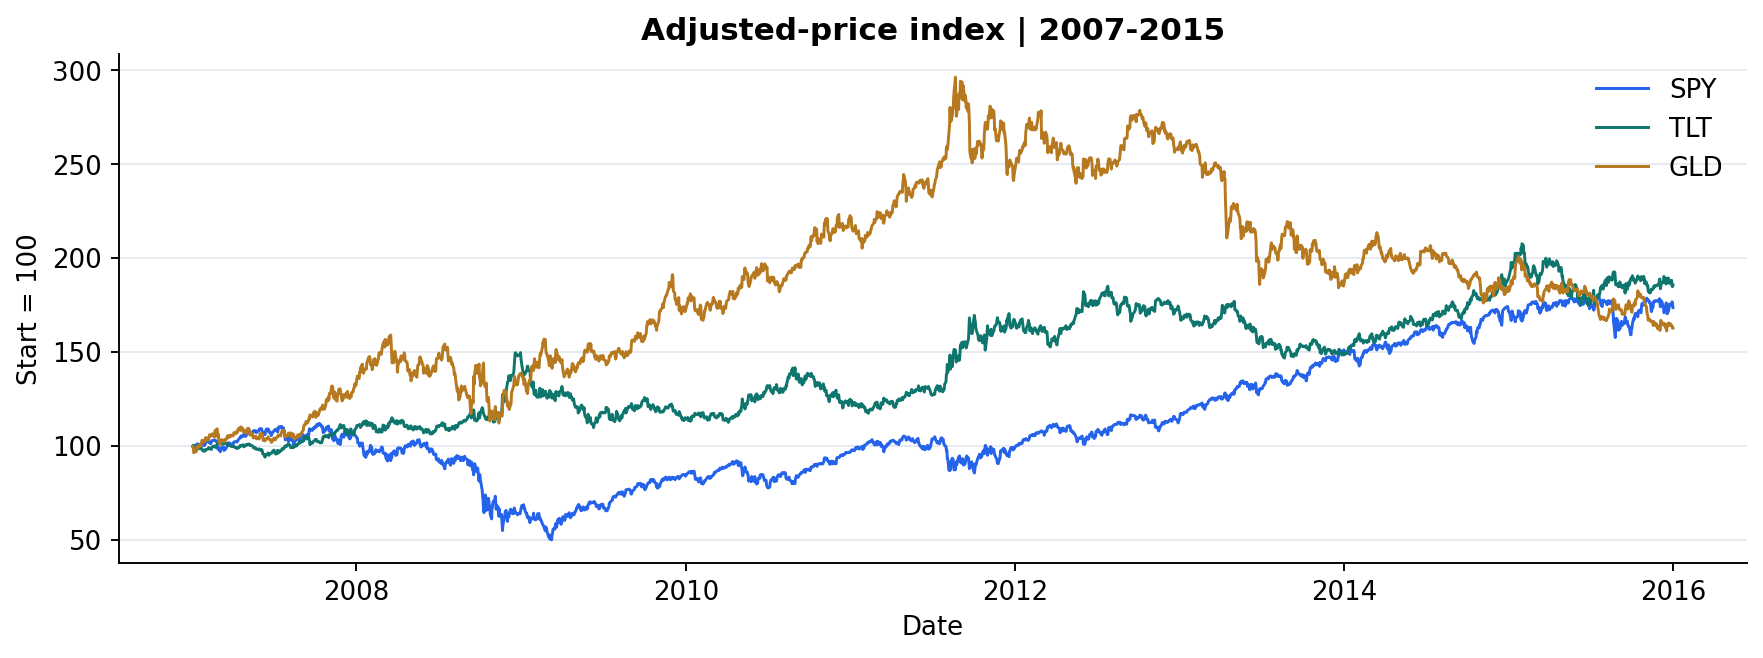

In [2]:
display(Image(filename=str(ROOT / 'reports/figures/initial_wealth.png')))


## 02 · Losses below each previous peak

High cumulative returns can conceal substantial interim losses. TLT and GLD also experience drawdowns, motivating a test of their defensive role.

**Method:** Current adjusted price divided by the highest price observed so far, minus one. Peaks before the sample start are excluded.


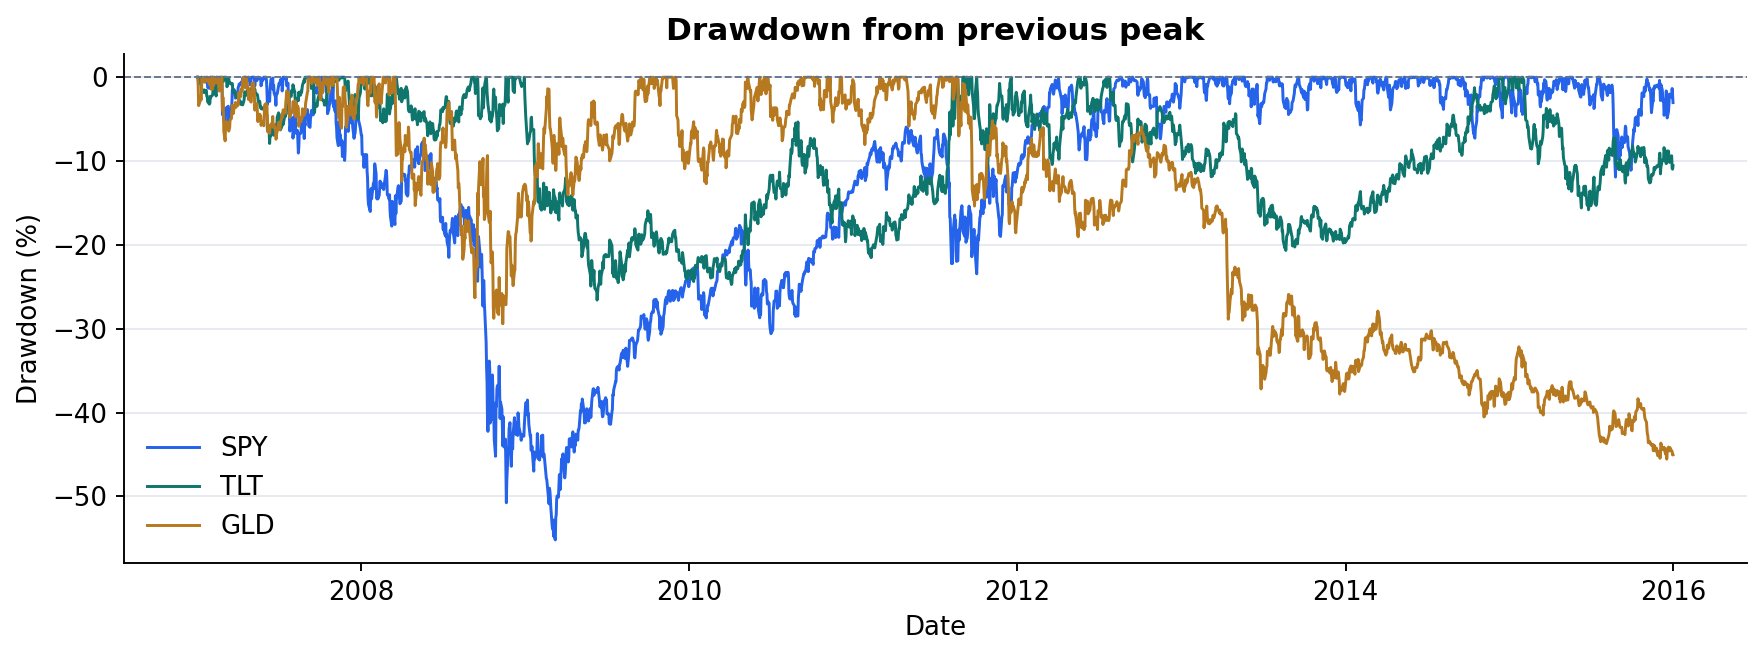

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/initial_drawdown.png')))


## 03 · Risk changes through time

Each asset alternates between quieter and more turbulent periods. This motivates comparing fixed allocations with risk-dependent exposure.

**Method:** Sample standard deviation of the trailing 21 daily simple returns, multiplied by the square root of 252. This is a backward-looking risk measure.


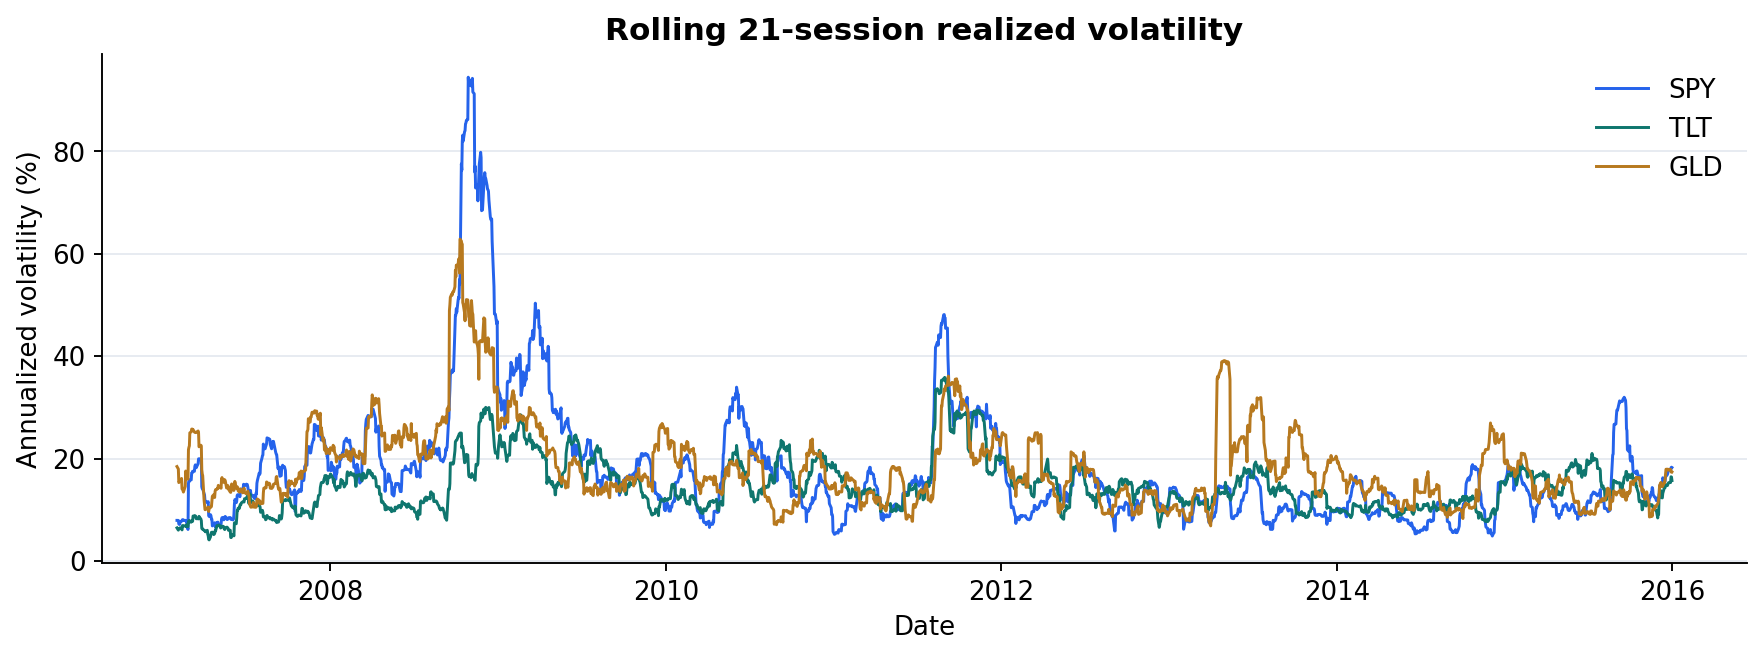

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/initial_volatility.png')))


## 04 · Diversification relationships change

The strength of the SPY/TLT relationship varies, as does the SPY/GLD relationship. Low correlation alone does not guarantee downside protection.

**Method:** Pearson correlation of contemporaneous daily returns over the trailing 126 sessions. No future observations enter this calculation.


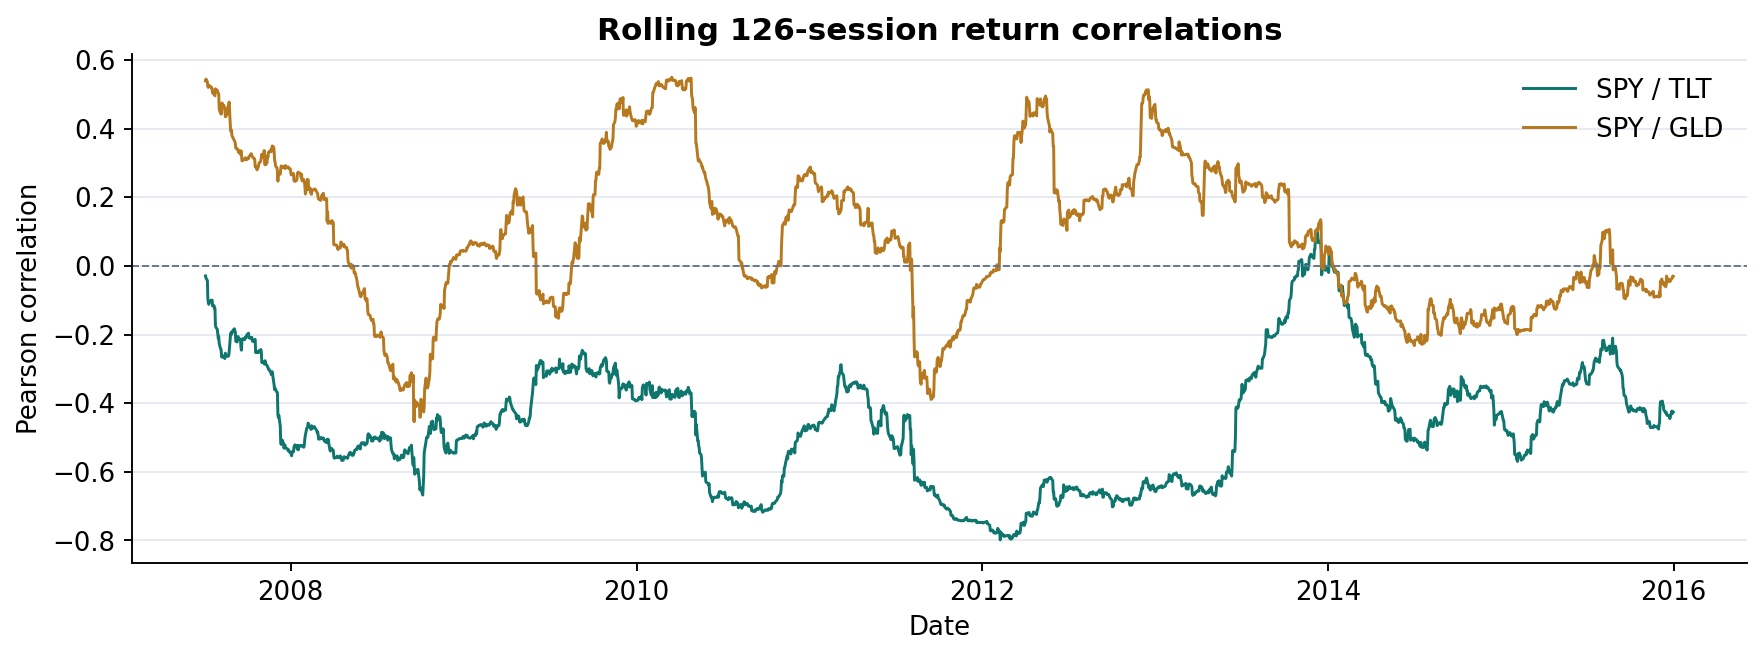

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/initial_correlation.png')))


## 05 · VIX and subsequent realized risk

Median subsequent volatility is 10.2% in the bottom VIX quartile and 20.7% in the top quartile, with 27 and 27 month-end observations. This does not establish return-direction predictability.

**Method:** Each point is a month-end. VIX is lagged by one session and matched to the annualized standard deviation of the following 20 returns. Some windows may overlap; no causal or significance claim is made.


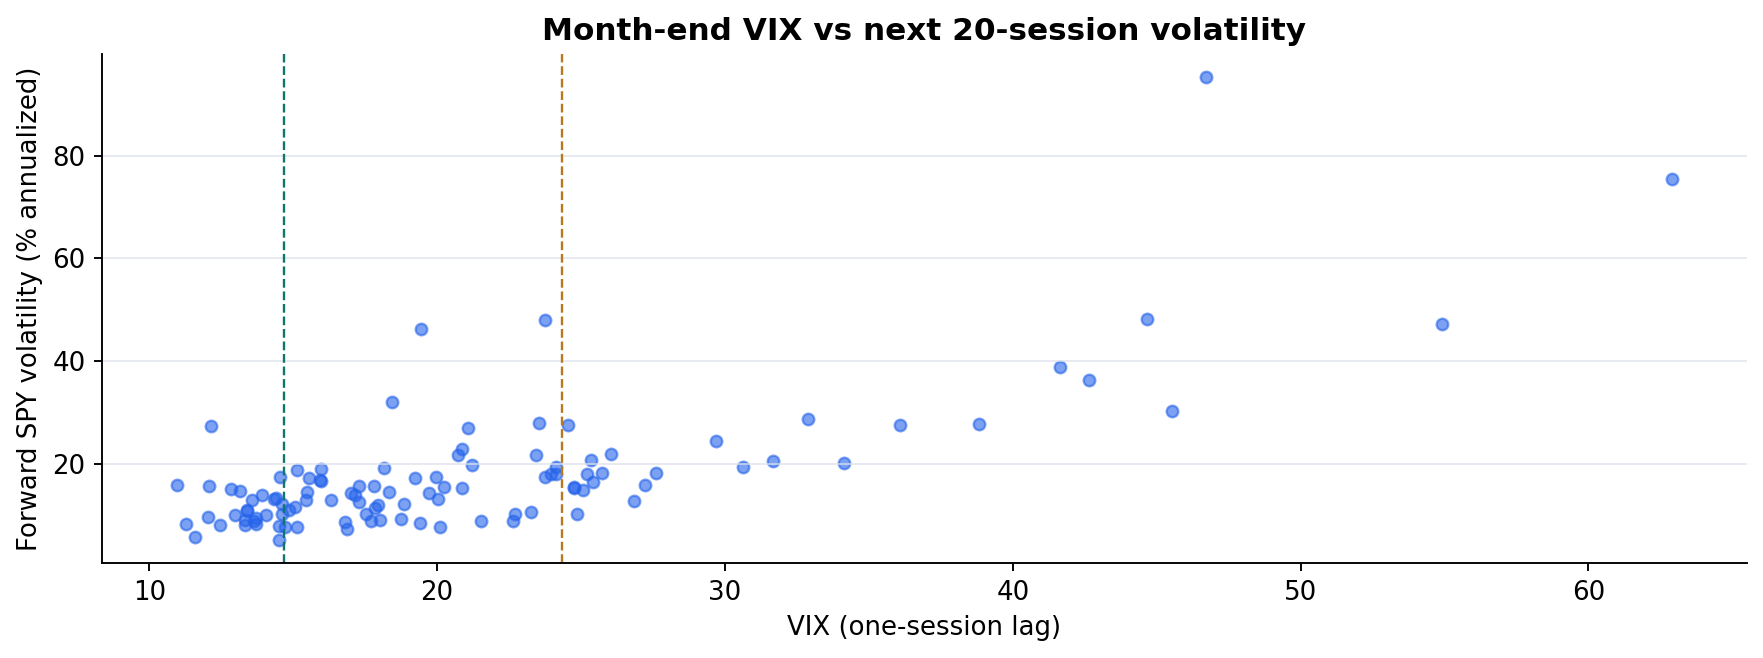

In [6]:
display(Image(filename=str(ROOT / 'reports/figures/initial_vix_forward.png')))


## 06 · Stress-day averages and distributions

Across 114 worst-5% SPY days, TLT averaged +1.22% and GLD -0.17%. Dispersion and extreme outcomes matter alongside the average response.

**Method:** Days are selected retrospectively using the development-sample fifth percentile of SPY returns (-2.05%). These are contemporaneous descriptive outcomes, not identifiable trading signals. Boxes show the interquartile range, the central line is the median, and means and outliers are shown separately.


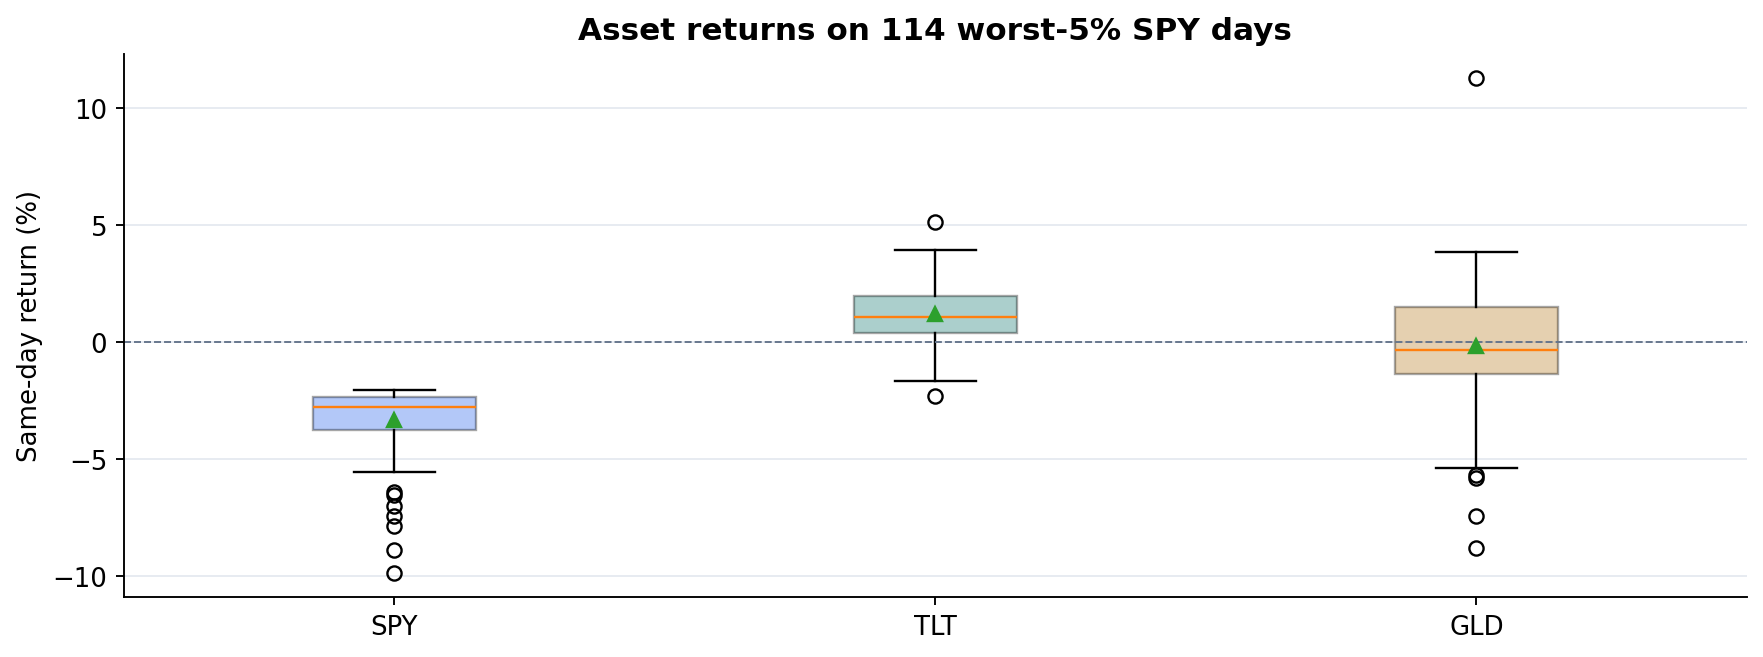

In [7]:
display(Image(filename=str(ROOT / 'reports/figures/initial_stress.png')))


## Sources and scope

ETF: [Pinned mirror](https://github.com/manisahni/marketdata/tree/65a079329e379e104495f459e12e76a8f995585a), VIX and rates: [FRED](https://fred.stlouisfed.org/series/VIXCLS). Source hashes are recorded in `data/raw/sources.json` . This analysis is descriptive and does not establish strategy alpha or causality.
